In [5]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [6]:
#Grabing the cleaned train/val/test data found in preprocessing data
import pandas as pd
path = '/content/drive/MyDrive/DeepMinds/'

X_train = pd.read_csv(path+'X_train.csv'); y_train = pd.read_csv(path+'y_train.csv').squeeze()
X_val   = pd.read_csv(path+'X_val.csv');   y_val   = pd.read_csv(path+'y_val.csv').squeeze()
X_test  = pd.read_csv(path+'X_test.csv');  y_test  = pd.read_csv(path+'y_test.csv').squeeze()

print(X_train.shape, X_val.shape, X_test.shape)

(165056, 50) (35369, 50) (35370, 50)


In [7]:
#Shared grading function so every model gets scored the same way
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

def evaluate(name, y_true, y_pred, y_prob):
    results = {
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1': f1_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
    }
    print(results)
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=['Legit', 'Phishing'])
    plt.title(name); plt.show()
    return results

In [8]:
#Building an MLP of any size, then make a 64 → 32 one to start
import tensorflow as tf
from tensorflow import keras
tf.keras.utils.set_random_seed(42)

def build_mlp(hidden_layers):
    model = keras.Sequential([keras.Input(shape=(X_train.shape[1],))])
    for units in hidden_layers:
        model.add(keras.layers.Dense(units, activation='relu'))
    model.add(keras.layers.Dense(1, activation='sigmoid'))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss='binary_crossentropy', metrics=['accuracy'])
    return model

model = build_mlp([64, 32])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         3,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,377 (21.00 KB)

 Trainable params: 5,377 (21.00 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
#Training for 20 epochs, checking validation as we go
history = model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=20, batch_size=256)

Epoch 1/20
645/645 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9937 - loss: 0.0266 - val_accuracy: 0.9997 - val_loss: 0.0011
Epoch 2/20
645/645 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9998 - loss: 7.6788e-04 - val_accuracy: 0.9999 - val_loss: 4.5724e-04
Epoch 3/20
645/645 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9999 - loss: 3.8936e-04 - val_accuracy: 0.9999 - val_loss: 2.9803e-04
Epoch 4/20
645/645 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9999 - loss: 2.8128e-04 - val_accuracy: 0.9999 - val_loss: 2.4343e-04
Epoch 5/20
645/645 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9999 - loss: 2.3222e-04 - val_accuracy: 0.9999 - val_loss: 2.1562e-04
Epoch 6/20
645/645 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9999 - loss: 2.0778e-04 - val_accuracy: 0.9999 - val_loss: 2.1579e-04
Epoch 7/20
645/645 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 1.0000 - loss: 1.8037e-04 - val_accuracy: 0.9999 - val_loss: 2.0460e-04
Epoch 8/20
645/645 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - ac

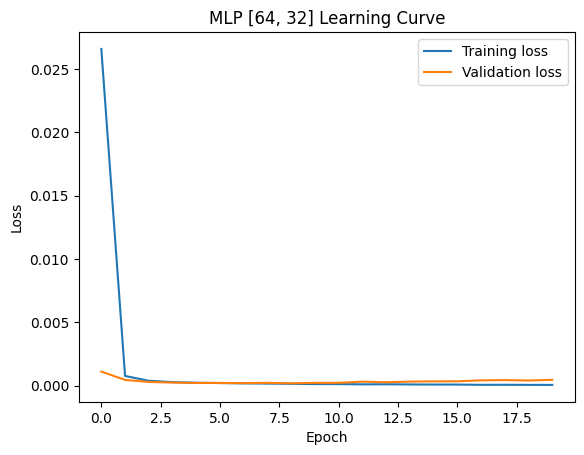

In [10]:
# Now we are plotting the learning curve to check for overfitting (and save it for the 3 page checkin/report thing)
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.title('MLP [64, 32] Learning Curve')
plt.legend()
plt.savefig(path+'mlp_loss_curve.png', dpi=200)
plt.show()

1106/1106 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step
{'Model': 'MLP [64, 32]', 'Accuracy': 0.9998869098105739, 'Precision': 1.0, 'Recall': 0.9997358341038172, 'F1': 0.9998678996036988, 'ROC-AUC': np.float64(0.9999992131700985)}


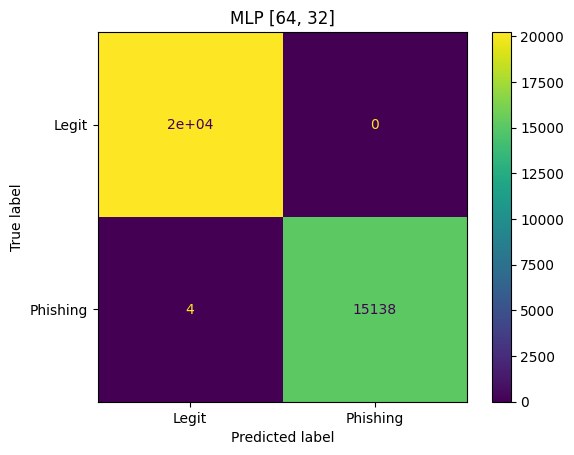

In [11]:
#Scoring the model on the test set (0.5+ probability = phishing) (below that = not)
probs = model.predict(X_test).ravel()
preds = (probs >= 0.5).astype(int)
mlp_results = evaluate('MLP [64, 32]', y_test, preds, probs)